<p align="center">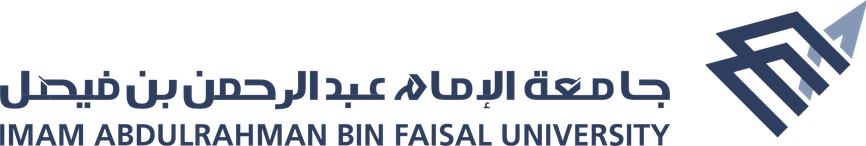</p>

# SMS Spam Detection - TF-IDF vs Sentence-BERT
**ARTI 404 - Natural Language Processing | Section 7MA2 | Group 9**
Instructor: Dr. Mohammed Mosuily

| Name | Student ID | Responsibilities |
|---|---|---|
| Mohammed Nasser Almarhoon (team leader) | 2240005893 | Data loading and cleaning, stratified split, Method 1 (TF-IDF + LR) and tuning, challenge-subset rules, Method 1 error analysis, original examples, GitHub repository |
| Ali Zuhair Alsaffar | 2240005706 | Method 2 (SBERT + LR) and tuning, evaluation (accuracy, macro F1, confusion matrices, McNemar, five splits), Method 2 error analysis, Try it cell, Colab setup |

**Task:** the input is one short English SMS, the output is *Spam* or *Not spam*.

**Research question:** which method detects misspelled / obfuscated spam (fr33, w1n, cl4im, txt, msg) more reliably: TF-IDF + Logistic Regression or Sentence-BERT + Logistic Regression?

## Contents
1. Setup
2. Helper functions
3. Data (loading, cleaning, split)
4. Method 1 - TF-IDF + Logistic Regression
5. Method 2 - Sentence-BERT + Logistic Regression
6. Results
   - 6.1 Full test set
   - 6.2 Challenge subset
   - 6.3 Extra test: obfuscated spam
   - 6.4 Extra test: obfuscated ham
   - 6.5 Statistical significance (McNemar test)
   - 6.6 Five random splits
7. Error analysis
8. Try it
9. Conclusion
10. Save result tables
11. Sources

## 1. Setup
**Environment:** Google Colab, Python 3, standard CPU runtime (no GPU needed). The whole notebook runs in a few minutes.

**How to reproduce:** *Runtime → Restart session and run all.* The dataset is downloaded from UCI (or read from `data/SMSSpamCollection.tsv` if present) and the pretrained model is downloaded from Hugging Face automatically. All paths are relative.

In [ ]:
# sentence-transformers is the only library that is not already installed on Colab
!pip install -q sentence-transformers

In [2]:
import os, re, io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sentence_transformers import SentenceTransformer

pd.set_option("display.max_colwidth", 120)

In [ ]:
# package versions used in this run
import sys, sklearn, scipy, matplotlib, torch, sentence_transformers
print("python               ", sys.version.split()[0])
for name, mod in [("scikit-learn", sklearn), ("sentence-transformers", sentence_transformers), ("torch", torch),
                  ("pandas", pd), ("numpy", np), ("scipy", scipy), ("matplotlib", matplotlib)]:
    print(f"{name:21s}", mod.__version__)

In [4]:
# ---------------- settings (all in one place) ----------------
SEED       = 42                                  # main split
SEEDS      = [42, 1, 7, 21, 100]                 # for the 5-split experiment (6.6)
C_GRID     = [0.01, 0.1, 1, 10, 100, 1000]       # regularization values tried on dev
MIN_DF_GRID = [1, 2]                             # TF-IDF min document frequency tried on dev
P_LEVELS   = [0.0, 0.1, 0.25, 0.5]               # share of letters replaced in 6.3 / 6.4

MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
UCI_URL    = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
LOCAL_FILE = "data/SMSSpamCollection.tsv"        # used instead of downloading if it exists

# spam-like words for rule 4 of the challenge subset
KEYWORDS = {"free", "win", "winner", "won", "prize", "claim", "cash", "urgent", "award", "awarded",
            "guaranteed", "bonus", "offer", "reward", "selected", "congratulations", "congrats"}

# letter substitutions used to obfuscate messages ourselves
LEET = {"e": "3", "i": "1", "o": "0", "a": "4", "s": "5"}

np.random.seed(SEED)

## 2. Helper functions
All small functions used later in the notebook.

In [5]:
# ---------- data ----------
def load_sms():
    """Load the SMS Spam Collection as a DataFrame with columns label, text."""
    if os.path.exists(LOCAL_FILE):
        txt = open(LOCAL_FILE, encoding="utf-8").read()
        print("loaded from", LOCAL_FILE)
    else:
        raw = urllib.request.urlopen(UCI_URL, timeout=30).read()
        with zipfile.ZipFile(io.BytesIO(raw)) as z:
            txt = z.read("SMSSpamCollection").decode("utf-8")
        print("loaded from UCI")
    rows = [line.split("\t", 1) for line in txt.splitlines() if "\t" in line]
    return pd.DataFrame(rows, columns=["label", "text"])

# ---------- models ----------
def make_tfidf(min_df):
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=min_df, sublinear_tf=True)

def make_lr(C, seed, max_iter):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=max_iter, random_state=seed)

def macro_f1(y, p):
    return f1_score(y, p, average="macro")

# ---------- challenge-subset rules ----------
def tokens(t):
    return re.findall(r"[a-z0-9]+", t.lower())

def has_digit_in_word(t):     # rule 1: fr33, w1n, 2nite
    return any(re.search(r"[a-z]", w) and re.search(r"\d", w) for w in tokens(t))

def has_repeat(t):            # rule 2: sooo, freeee
    return re.search(r"([a-z])\1\1", t.lower()) is not None

def has_novowel(t):           # rule 3: txt, msg, pls
    return any(len(w) >= 3 and w.isalpha() and not re.search(r"[aeiouy]", w) for w in tokens(t))

def has_keyword(t):           # rule 4: free, win, prize ...
    return any(w in KEYWORDS for w in tokens(t))

def flags(t):
    return {"digit_in_word": has_digit_in_word(t), "repeat": has_repeat(t),
            "no_vowel": has_novowel(t), "keyword": has_keyword(t)}

# ---------- obfuscation ----------
def leetify(t, p, rng):
    """Replace letters (e->3, i->1, o->0, a->4, s->5), each with probability p."""
    return "".join(LEET[c.lower()] if c.lower() in LEET and rng.random() < p else c for c in t)

# ---------- statistics ----------
def mcnemar(y, p1, p2):
    """Exact McNemar test. b = only method 1 right, c = only method 2 right."""
    r1, r2 = (p1 == y), (p2 == y)
    b = int((r1 & ~r2).sum()); c = int((~r1 & r2).sum())
    pval = binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0
    return b, c, pval

## 3. Data
UCI SMS Spam Collection (Almeida et al., 2011): 5,574 English SMS messages labelled ham or spam.

### 3.1 Loading

In [6]:
df = load_sms()
print(df.shape)
df.head()

loaded from data/SMSSpamCollection.tsv
(5574, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


label
ham     4827
spam     747
Name: count, dtype: int64


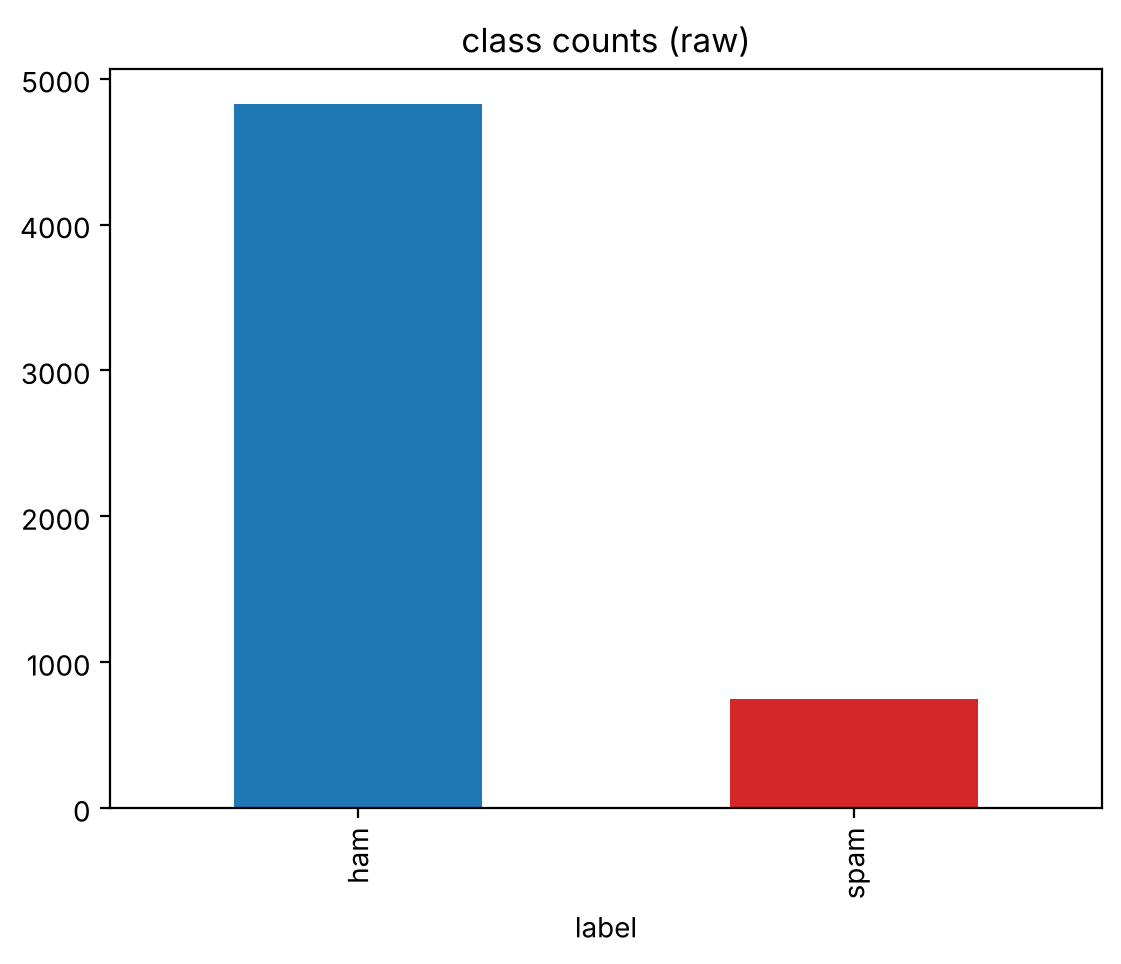

In [7]:
print(df["label"].value_counts())
df["label"].value_counts().plot(kind="bar", title="class counts (raw)", color=["tab:blue", "tab:red"])
plt.show()

### 3.2 Cleaning
Empty rows and exact duplicates are removed **before** splitting, so the same message can't be in both train and test.

In [8]:
n0 = len(df)
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""]
n_empty = n0 - len(df)

n1 = len(df)
df = df.drop_duplicates(subset="text").reset_index(drop=True)
n_dup = n1 - len(df)

df["y"] = (df["label"] == "spam").astype(int)   # ham = 0, spam = 1

print("raw rows        :", n0)
print("empty removed   :", n_empty)
print("dupes removed   :", n_dup)
print("after cleaning  :", len(df))
print(df["label"].value_counts())
print("spam ratio      : %.3f" % df["y"].mean())

raw rows        : 5574
empty removed   : 0
dupes removed   : 414
after cleaning  : 5160
label
ham     4518
spam     642
Name: count, dtype: int64
spam ratio      : 0.124


### 3.3 Train / dev / test split (≈70/15/15, stratified)

In [9]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=SEED)
dev_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["y"], random_state=SEED)

for name, d in [("train", train_df), ("dev", dev_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):5d} msgs | spam = {d['y'].sum():4d} ({d['y'].mean():.3f})")

X_train, y_train = train_df["text"].tolist(), train_df["y"].values
X_dev,   y_dev   = dev_df["text"].tolist(),   dev_df["y"].values
X_test,  y_test  = test_df["text"].tolist(),  test_df["y"].values

train:  3612 msgs | spam =  449 (0.124)
dev  :   774 msgs | spam =   97 (0.125)
test :   774 msgs | spam =   96 (0.124)


## 4. Method 1 - TF-IDF + Logistic Regression
Word unigrams + bigrams, lowercased, sublinear TF. `class_weight='balanced'` because spam is only ~12% of the data.
`C` and `min_df` are tuned on the **dev** set only.

In [10]:
m1_results = []
for min_df in MIN_DF_GRID:
    for C in C_GRID:
        vec = make_tfidf(min_df)
        clf = make_lr(C, SEED, 2000).fit(vec.fit_transform(X_train), y_train)
        p = clf.predict(vec.transform(X_dev))
        m1_results.append({"min_df": min_df, "C": C, "dev_acc": accuracy_score(y_dev, p), "dev_macroF1": macro_f1(y_dev, p)})

m1_tab = pd.DataFrame(m1_results).sort_values("dev_macroF1", ascending=False)
m1_tab

,min_df,C,dev_acc,dev_macroF1
4,1,100.00,0.984496,0.964641
10,2,100.00,0.984496,0.964325
9,2,10.00,0.983204,0.961863
3,1,10.00,0.980620,0.956377
8,2,1.00,0.980620,0.956377
5,1,1000.00,0.980620,0.956377
2,1,1.00,0.978036,0.950985
11,2,1000.00,0.978036,0.949685
0,1,0.01,0.975452,0.944745
1,1,0.10,0.974160,0.942088


In [11]:
best1 = m1_tab.iloc[0]
print("best on dev ->", dict(best1))

tfidf = make_tfidf(int(best1["min_df"]))
m1 = make_lr(float(best1["C"]), SEED, 2000).fit(tfidf.fit_transform(X_train), y_train)
print("vocab size:", len(tfidf.vocabulary_))

best on dev -> {'min_df': np.float64(1.0), 'C': np.float64(100.0), 'dev_acc': np.float64(0.9844961240310077), 'dev_macroF1': np.float64(0.9646408503251154)}
vocab size: 38364


In [12]:
# what the model learned: strongest words for spam and for ham
feat = np.array(tfidf.get_feature_names_out())
w = m1.coef_[0]
print("most spammy :", list(feat[np.argsort(w)[-20:][::-1]]))
print("most hammy  :", list(feat[np.argsort(w)[:20]]))

most spammy : ['call', 'txt', 'text', 'free', 'uk', 'reply', 'claim', 'stop', 'www', 'to', '150p', 'mobile', 'service', '50', 'prize', 'com', '146tf150p', 'won', 'ringtone', 'your']
most hammy  : ['me', 'my', 'your call', 'can', 'that', 'ok', 'gt', 'lt', 'but', 'it', 'lt gt', 'am', 'got', 'how', 'when', 'da', 'he', 'then', 'sorry', 'call me']


## 5. Method 2 - Sentence-BERT + Logistic Regression
`all-MiniLM-L6-v2` with **frozen weights** (we only call `encode`, no fine-tuning). Each SMS becomes a 384-dim vector,
then the same Logistic Regression is trained on top. `C` is tuned on the **dev** set only.

In [13]:
sbert = SentenceTransformer(MODEL_NAME, device="cpu")
print("embedding size:", sbert.get_sentence_embedding_dimension())

def embed(texts):
    return sbert.encode(texts, batch_size=64, show_progress_bar=False, normalize_embeddings=True)

# encoding takes about 1-2 minutes on the Colab CPU
E_train, E_dev, E_test = embed(X_train), embed(X_dev), embed(X_test)
print(E_train.shape, E_dev.shape, E_test.shape)

embedding size: 384


(3612, 384) (774, 384) (774, 384)


In [14]:
m2_results = []
for C in C_GRID:
    p = make_lr(C, SEED, 5000).fit(E_train, y_train).predict(E_dev)
    m2_results.append({"C": C, "dev_acc": accuracy_score(y_dev, p), "dev_macroF1": macro_f1(y_dev, p)})

m2_tab = pd.DataFrame(m2_results).sort_values("dev_macroF1", ascending=False)
m2_tab

,C,dev_acc,dev_macroF1
4,100.00,0.984496,0.964950
5,1000.00,0.984496,0.964950
3,10.00,0.976744,0.949186
2,1.00,0.971576,0.938906
1,0.10,0.963824,0.923483
0,0.01,0.945736,0.888732


In [15]:
best2 = m2_tab.iloc[0]
print("best on dev ->", dict(best2))
m2 = make_lr(float(best2["C"]), SEED, 5000).fit(E_train, y_train)

best on dev -> {'C': np.float64(100.0), 'dev_acc': np.float64(0.9844961240310077), 'dev_macroF1': np.float64(0.9649498852795556)}


## 6. Results
The test set is used here for the first time, with all hyperparameters already fixed on dev.

### 6.1 Full test set

In [16]:
pred1 = m1.predict(tfidf.transform(X_test))
pred2 = m2.predict(E_test)

results = pd.DataFrame([
    {"method": "M1: TF-IDF + LR", "accuracy": accuracy_score(y_test, pred1), "macro_F1": macro_f1(y_test, pred1)},
    {"method": "M2: SBERT + LR",  "accuracy": accuracy_score(y_test, pred2), "macro_F1": macro_f1(y_test, pred2)},
]).round(4)
results

,method,accuracy,macro_F1
0,M1: TF-IDF + LR,0.9845,0.9640
1,M2: SBERT + LR,0.9780,0.9501


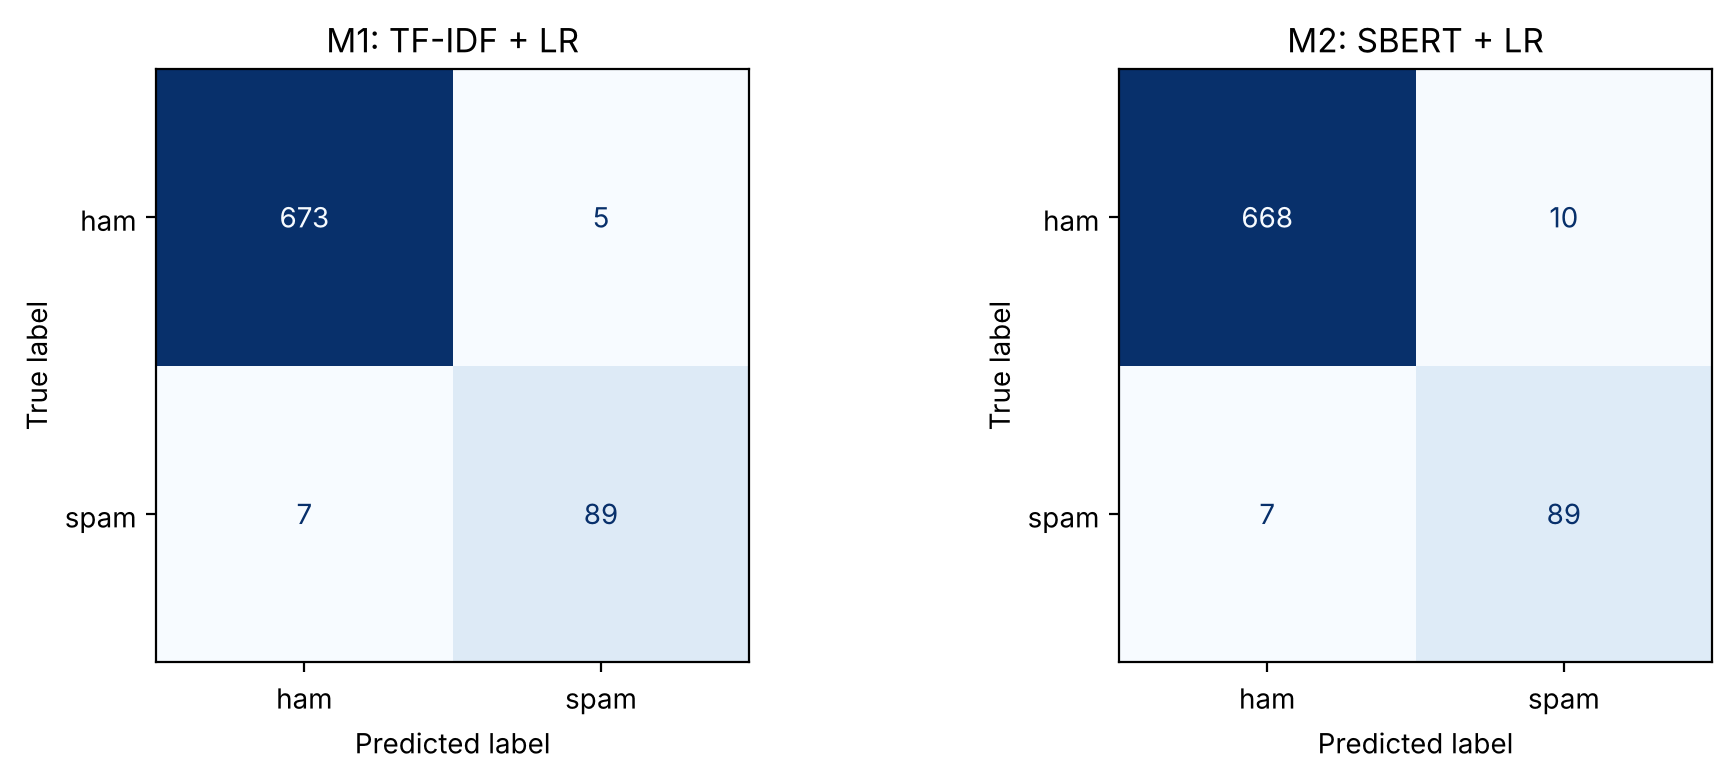

M1
               precision    recall  f1-score   support

         ham      0.990     0.993     0.991       678
        spam      0.947     0.927     0.937        96

    accuracy                          0.984       774
   macro avg      0.968     0.960     0.964       774
weighted avg      0.984     0.984     0.984       774

M2
               precision    recall  f1-score   support

         ham      0.990     0.985     0.987       678
        spam      0.899     0.927     0.913        96

    accuracy                          0.978       774
   macro avg      0.944     0.956     0.950       774
weighted avg      0.978     0.978     0.978       774



In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, p, t in [(ax[0], pred1, "M1: TF-IDF + LR"), (ax[1], pred2, "M2: SBERT + LR")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["ham", "spam"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(t)
plt.tight_layout(); plt.show()

print("M1\n", classification_report(y_test, pred1, target_names=["ham", "spam"], digits=3))
print("M2\n", classification_report(y_test, pred2, target_names=["ham", "spam"], digits=3))

### 6.2 Challenge subset
A test message is flagged if it matches at least one fixed rule (written before looking at the results):
1. **digit inside a word** - a token with both letters and digits (fr33, w1n, 2nite, 4u)
2. **repeated characters** - the same letter 3+ times in a row (sooo, freeee)
3. **no-vowel token** of length ≥ 3, letters only (txt, msg, pls)
4. **spam keyword** (free, win, prize, claim, cash, urgent, ...) - covers *ham* messages that also use spam-like words

We first count the flagged messages. We also report a stricter **obfuscated only** subset (rules 1-3).

In [18]:
F = pd.DataFrame([flags(t) for t in X_test], index=test_df.index)
test_df = test_df.join(F)
test_df["obfuscated"] = F[["digit_in_word", "repeat", "no_vowel"]].any(axis=1)
test_df["challenge"]  = F.any(axis=1)
test_df["pred1"], test_df["pred2"] = pred1, pred2

print("flag counts on test set:")
print(F.sum())
print("\nchallenge subset size:", test_df["challenge"].sum(), "of", len(test_df))
print(pd.crosstab(test_df["challenge"], test_df["label"]))

flag counts on test set:
digit_in_word     92
repeat            23
no_vowel         121
keyword           63
dtype: int64

challenge subset size: 205 of 774
label      ham  spam
challenge           
False      554    15
True       124    81


In [19]:
# a few flagged examples, to check that the rules make sense
test_df[test_df["challenge"]][["label", "text", "digit_in_word", "repeat", "no_vowel", "keyword"]].sample(8, random_state=1)

,label,text,digit_in_word,repeat,no_vowel,keyword
4409,spam,"Had your mobile 10 mths? Update to the latest Camera/Video phones for FREE. KEEP UR SAME NUMBER, Get extra free mins...",False,False,True,True
3763,ham,"Forgot you were working today! Wanna chat, but things are ok so drop me a text when you're free / bored etc and i'll...",False,False,False,True
2126,ham,"Goodmorning, today i am late for 2hrs. Because of back pain.",True,False,False,False
366,ham,I'm going for bath will msg you next &lt;#&gt; min..,False,False,True,False
4647,ham,I'm hungry buy smth home...,False,False,True,False
1201,ham,Is ur paper in e morn or aft tmr?,False,False,True,False
4956,spam,"u r subscribed 2 TEXTCOMP 250 wkly comp. 1st wk?s free question follows, subsequent wks charged@150p/msg.2 unsubscri...",True,False,True,True
2315,ham,"Madam,regret disturbance.might receive a reference check from DLF Premarica.kindly be informed.Rgds,Rakhesh,Kerala.",False,False,True,False


The subset is big enough for a comparison (both classes are present), so the definition is kept.

In [20]:
def subset_scores(mask, name):
    d = test_df[mask]
    return [{"subset": name, "n": len(d), "n_spam": int(d["y"].sum()), "method": m,
             "accuracy": accuracy_score(d["y"], d[col]), "macro_F1": macro_f1(d["y"], d[col]),
             "errors": int((d["y"] != d[col]).sum())}
            for m, col in [("M1: TF-IDF + LR", "pred1"), ("M2: SBERT + LR", "pred2")]]

rows = []
rows += subset_scores(test_df.index == test_df.index, "full test")
rows += subset_scores(test_df["challenge"], "challenge (all 4 rules)")
rows += subset_scores(test_df["obfuscated"], "obfuscated only (rules 1-3)")
rows += subset_scores(~test_df["challenge"], "not flagged")
sub_res = pd.DataFrame(rows).round(4)
sub_res

,subset,n,n_spam,method,accuracy,macro_F1,errors
0,full test,774,96,M1: TF-IDF + LR,0.9845,0.9640,12
1,full test,774,96,M2: SBERT + LR,0.9780,0.9501,17
2,challenge (all 4 rules),205,81,M1: TF-IDF + LR,0.9561,0.9538,9
3,challenge (all 4 rules),205,81,M2: SBERT + LR,0.9707,0.9694,6
4,obfuscated only (rules 1-3),184,73,M1: TF-IDF + LR,0.9620,0.9598,7
5,obfuscated only (rules 1-3),184,73,M2: SBERT + LR,0.9837,0.9829,3
6,not flagged,569,15,M1: TF-IDF + LR,0.9947,0.9503,3
7,not flagged,569,15,M2: SBERT + LR,0.9807,0.8284,11


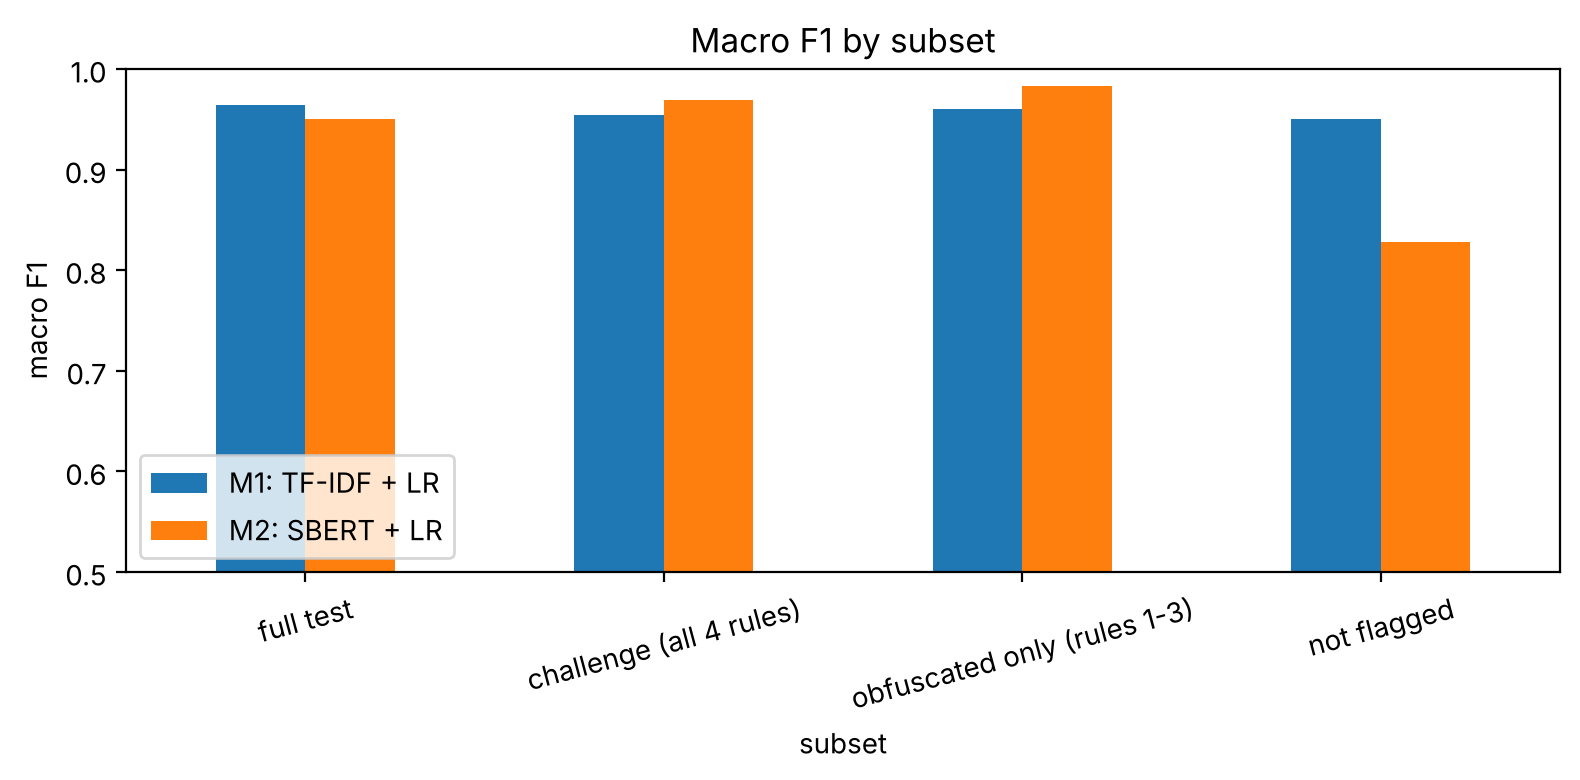

In [21]:
piv = sub_res.pivot(index="subset", columns="method", values="macro_F1").loc[
    ["full test", "challenge (all 4 rules)", "obfuscated only (rules 1-3)", "not flagged"]]
piv.plot(kind="bar", figsize=(8, 4), ylim=(0.5, 1.0), rot=15, title="Macro F1 by subset")
plt.ylabel("macro F1"); plt.legend(loc="lower left"); plt.tight_layout(); plt.show()

In [22]:
# spam caught inside the challenge subset, and false alarms on ham that contains a spam keyword
ch = test_df[test_df["challenge"] & (test_df["y"] == 1)]
print("spam msgs in challenge subset:", len(ch))
print("M1 caught:", int(ch["pred1"].sum()), " | M2 caught:", int(ch["pred2"].sum()))

hc = test_df[test_df["keyword"] & (test_df["y"] == 0)]
print("\nham msgs that contain a spam keyword:", len(hc))
print("M1 false alarms:", int(hc["pred1"].sum()), " | M2 false alarms:", int(hc["pred2"].sum()))

spam msgs in challenge subset: 81
M1 caught: 75  | M2 caught: 78

ham msgs that contain a spam keyword: 17
M1 false alarms: 3  | M2 false alarms: 3


**What we see:** with this split SBERT is better on the challenge subset and on the obfuscated-only part, while TF-IDF is clearly better on the messages that are not flagged. The gap on the challenge subset is only a few messages, so 6.5 and 6.6 check whether it is real.

### 6.3 Extra test: obfuscated spam
We replace letters in the **spam** messages of the test set (e→3, i→1, o→0, a→4, s→5) with probability `p` and measure spam recall. The models are not retrained.

In [23]:
spam_test = test_df[test_df["y"] == 1]["text"].tolist()
rows = []
for p in P_LEVELS:
    rng = np.random.default_rng(SEED)
    obf = [leetify(t, p, rng) for t in spam_test]
    rows.append({"p_replace": p,
                 "M1 spam recall": round(m1.predict(tfidf.transform(obf)).mean(), 3),
                 "M2 spam recall": round(m2.predict(embed(obf)).mean(), 3)})
leet_res = pd.DataFrame(rows)
print("example (p=0.25):", leetify(spam_test[0], 0.25, np.random.default_rng(SEED)))
leet_res

example (p=0.25): WINNER!! As 4 valued netw0rk customer you have b3en 5elected to receiv3a £900 pr1z3 reward! To claim call 09061701461. Cl41m cod3 KL341. Valid 12 hours only.


,p_replace,M1 spam recall,M2 spam recall
0,0.00,0.927,0.927
1,0.10,0.927,0.938
2,0.25,0.906,0.938
3,0.50,0.823,0.969


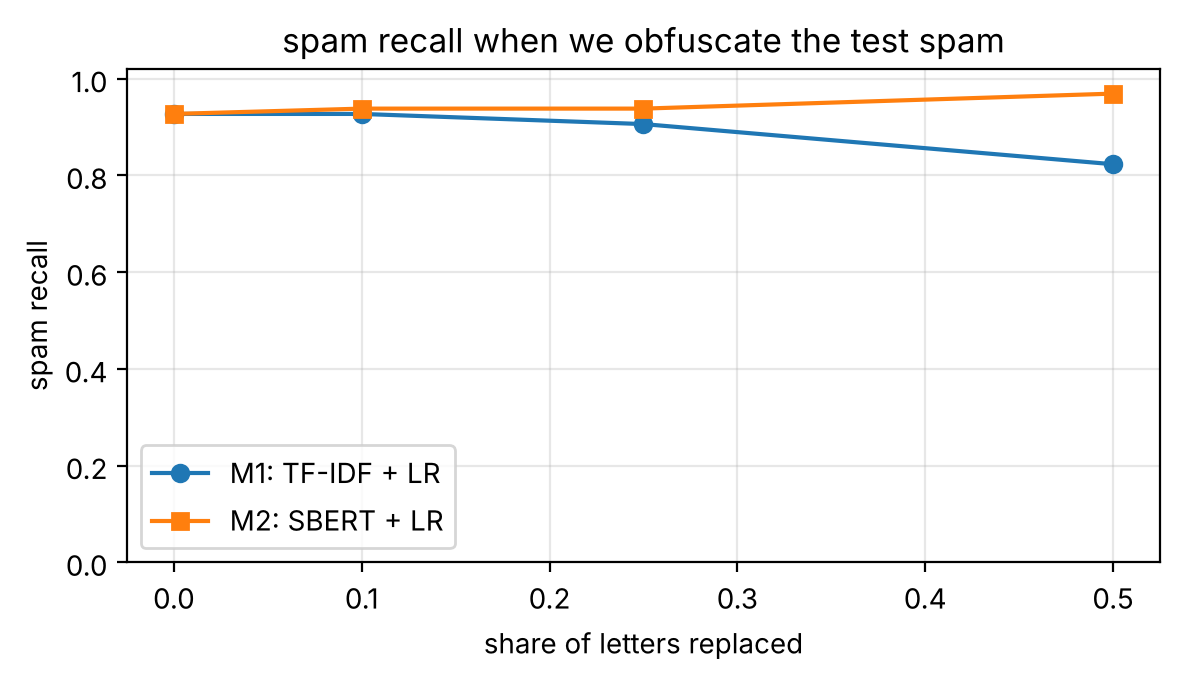

In [24]:
plt.figure(figsize=(6, 3.5))
plt.plot(leet_res["p_replace"], leet_res["M1 spam recall"], "o-", label="M1: TF-IDF + LR")
plt.plot(leet_res["p_replace"], leet_res["M2 spam recall"], "s-", label="M2: SBERT + LR")
plt.xlabel("share of letters replaced"); plt.ylabel("spam recall"); plt.ylim(0, 1.02)
plt.title("spam recall when we obfuscate the test spam"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

**What we see:** TF-IDF drops as more letters are replaced, because a word like "pr1z3" is unknown to it. SBERT keeps a high recall because its tokenizer splits unknown words into pieces.

### 6.4 Extra test: obfuscated ham
Same letter replacement on the **ham** messages of the test set, to see if obfuscated text alone makes a model say spam (false alarms).

In [25]:
ham_test = test_df[test_df["y"] == 0]["text"].tolist()
rows = []
for p in P_LEVELS:
    rng = np.random.default_rng(SEED)
    obf = [leetify(t, p, rng) for t in ham_test]
    rows.append({"p_replace": p,
                 "M1 false alarm rate": round(m1.predict(tfidf.transform(obf)).mean(), 3),
                 "M2 false alarm rate": round(m2.predict(embed(obf)).mean(), 3)})
leet_ham_res = pd.DataFrame(rows)
print("ham messages:", len(ham_test))
leet_ham_res

ham messages: 678


,p_replace,M1 false alarm rate,M2 false alarm rate
0,0.00,0.007,0.015
1,0.10,0.009,0.024
2,0.25,0.015,0.052
3,0.50,0.025,0.119


**What we see:** TF-IDF barely changes, but SBERT's false alarms go up a lot (about 12% at p = 0.5). So part of SBERT's high spam recall in 6.3 is because obfuscated text in general looks spammy to it.

### 6.5 Statistical significance (McNemar test)
Both methods are tested on the **same** messages, so we use McNemar's exact test on the messages where they disagree:
`b` = only M1 right, `c` = only M2 right. A p-value below 0.05 means the difference is unlikely to be chance.

In [26]:
rows = []
for name, mask in [("full test", np.ones(len(test_df), bool)),
                   ("challenge (all 4 rules)", test_df["challenge"].values),
                   ("obfuscated only (rules 1-3)", test_df["obfuscated"].values)]:
    b, c, pv = mcnemar(test_df["y"].values[mask], pred1[mask], pred2[mask])
    rows.append({"subset": name, "M1 right / M2 wrong (b)": b, "M1 wrong / M2 right (c)": c, "p-value": round(pv, 3)})

# the 96 test spam messages with 50% of letters replaced (same messages for both models)
rng = np.random.default_rng(SEED)
obf_spam = [leetify(t, 0.5, rng) for t in spam_test]
b, c, pv = mcnemar(np.ones(len(obf_spam), int), m1.predict(tfidf.transform(obf_spam)), m2.predict(embed(obf_spam)))
rows.append({"subset": "spam, 50% letters obfuscated", "M1 right / M2 wrong (b)": b, "M1 wrong / M2 right (c)": c, "p-value": round(pv, 3)})

mcnemar_res = pd.DataFrame(rows)
mcnemar_res

,subset,M1 right / M2 wrong (b),M1 wrong / M2 right (c),p-value
0,full test,13,8,0.383
1,challenge (all 4 rules),3,6,0.508
2,obfuscated only (rules 1-3),1,5,0.219
3,"spam, 50% letters obfuscated",2,16,0.001


**What we see:** on the real test messages (full, challenge, obfuscated only) all p-values are above 0.05, so the differences could be chance. Only the heavy synthetic obfuscation gives a significant difference (SBERT catches more spam).

### 6.6 Five random splits
One split can be lucky or unlucky, so the whole pipeline (split → tune on dev → test) is repeated with 5 seeds.
The SBERT embeddings don't depend on the split, so they are computed once for all messages.

In [27]:
E_all   = embed(df["text"].tolist())
fl_all  = pd.DataFrame([flags(t) for t in df["text"]])
ch_all  = fl_all.any(axis=1).values
ob_all  = fl_all[["digit_in_word", "repeat", "no_vowel"]].any(axis=1).values
y_all   = df["y"].values
txt_all = df["text"].values

def run_seed(seed):
    idx = np.arange(len(df))
    tr, tmp = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=seed)
    dv, te  = train_test_split(tmp, test_size=0.50, stratify=y_all[tmp], random_state=seed)

    # method 1: tune C and min_df on dev
    best = (-1, None)
    for min_df in MIN_DF_GRID:
        for C in C_GRID:
            vec = make_tfidf(min_df)
            clf = make_lr(C, seed, 2000).fit(vec.fit_transform(txt_all[tr]), y_all[tr])
            f = macro_f1(y_all[dv], clf.predict(vec.transform(txt_all[dv])))
            if f > best[0]: best = (f, (vec, clf, C))
    vec, clf1, c1 = best[1]
    p1 = clf1.predict(vec.transform(txt_all[te]))

    # method 2: tune C on dev
    best = (-1, None)
    for C in C_GRID:
        clf = make_lr(C, seed, 5000).fit(E_all[tr], y_all[tr])
        f = macro_f1(y_all[dv], clf.predict(E_all[dv]))
        if f > best[0]: best = (f, (clf, C))
    clf2, c2 = best[1]
    p2 = clf2.predict(E_all[te])

    yt, ch, ob = y_all[te], ch_all[te], ob_all[te]
    return {"seed": seed, "M1 best C": c1, "M2 best C": c2,
            "M1 full F1": macro_f1(yt, p1), "M2 full F1": macro_f1(yt, p2),
            "M1 challenge F1": macro_f1(yt[ch], p1[ch]), "M2 challenge F1": macro_f1(yt[ch], p2[ch]),
            "M1 obfuscated F1": macro_f1(yt[ob], p1[ob]), "M2 obfuscated F1": macro_f1(yt[ob], p2[ob])}

seed_res = pd.DataFrame([run_seed(s) for s in SEEDS]).round(4)
seed_res

,seed,M1 best C,M2 best C,M1 full F1,M2 full F1,M1 challenge F1,M2 challenge F1,M1 obfuscated F1,M2 obfuscated F1
0,42,100,100,0.9640,0.9501,0.9538,0.9694,0.9598,0.9829
1,1,100,100,0.9764,0.9708,0.9802,0.9754,0.9783,0.9784
2,7,100,100,0.9789,0.9479,0.9843,0.9530,0.9879,0.9574
3,21,10,10,0.9726,0.9426,0.9784,0.9626,0.9813,0.9630
4,100,10,10,0.9700,0.9795,0.9698,0.9851,0.9831,0.9888


    subset  M1 mean  M1 std  M2 mean  M2 std  M2 better in (of 5)
      full   0.9724  0.0058   0.9582  0.0160                    1
 challenge   0.9733  0.0121   0.9691  0.0122                    2
obfuscated   0.9781  0.0108   0.9741  0.0134                    3


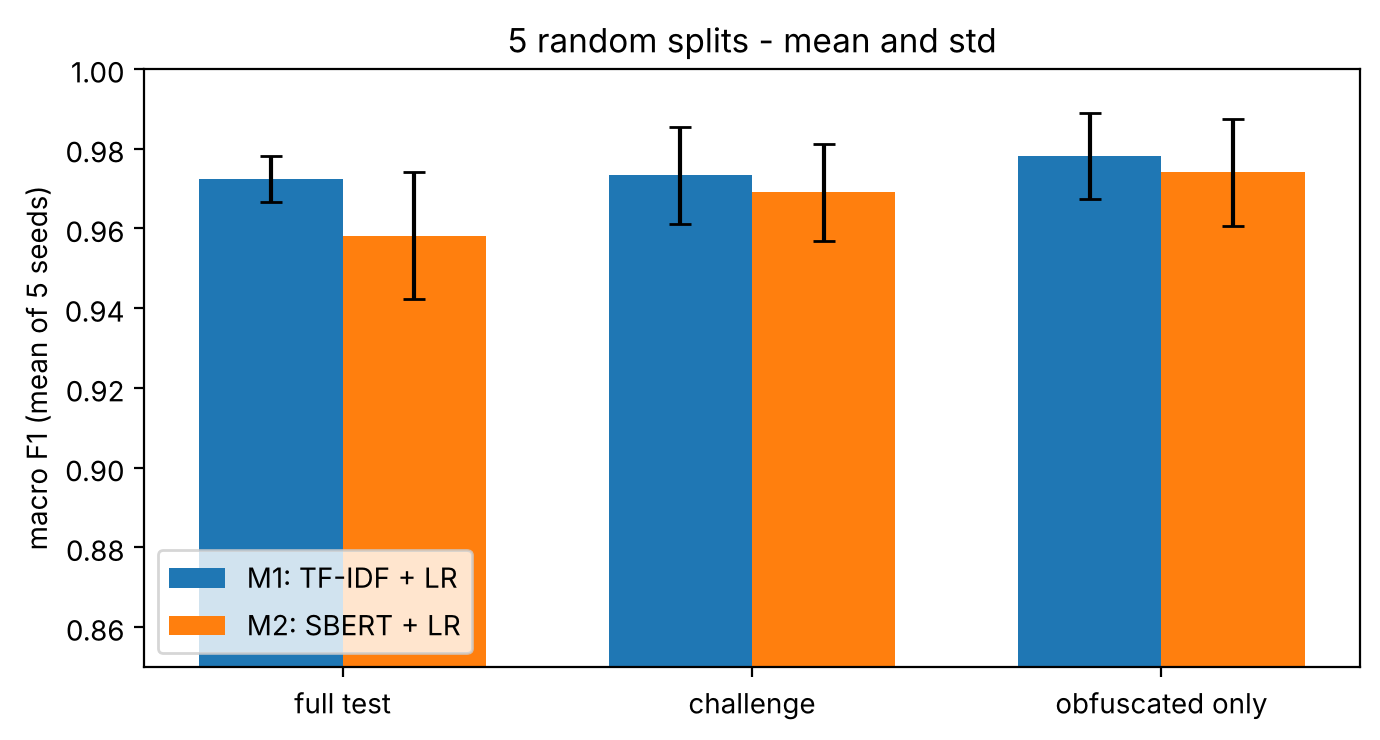

In [28]:
cols = ["full", "challenge", "obfuscated"]
summary = pd.DataFrame({
    "subset": cols,
    "M1 mean": [seed_res[f"M1 {c} F1"].mean() for c in cols],
    "M1 std":  [seed_res[f"M1 {c} F1"].std() for c in cols],
    "M2 mean": [seed_res[f"M2 {c} F1"].mean() for c in cols],
    "M2 std":  [seed_res[f"M2 {c} F1"].std() for c in cols],
    "M2 better in (of 5)": [int((seed_res[f"M2 {c} F1"] > seed_res[f"M1 {c} F1"]).sum()) for c in cols],
}).round(4)
print(summary.to_string(index=False))

x = np.arange(len(cols)); w = 0.35
plt.figure(figsize=(7, 3.8))
plt.bar(x - w/2, summary["M1 mean"], w, yerr=summary["M1 std"], capsize=4, label="M1: TF-IDF + LR")
plt.bar(x + w/2, summary["M2 mean"], w, yerr=summary["M2 std"], capsize=4, label="M2: SBERT + LR")
plt.xticks(x, ["full test", "challenge", "obfuscated only"]); plt.ylim(0.85, 1.0)
plt.ylabel("macro F1 (mean of 5 seeds)"); plt.title("5 random splits - mean and std")
plt.legend(loc="lower left"); plt.tight_layout(); plt.show()

**What we see:** the best C is 10 or 100 in every seed (never the edge of the grid). Over 5 splits TF-IDF is slightly better on average on all three sets, and SBERT only wins in some seeds. So SBERT's advantage on the challenge subset with seed 42 was partly luck of the split.

## 7. Error analysis
All wrong predictions of each method on the test set.

In [29]:
def errors_of(pred_col):
    e = test_df[test_df[pred_col] != test_df["y"]][["label", "text", "challenge"]].copy()
    e["M1_pred"] = np.where(test_df.loc[e.index, "pred1"] == 1, "spam", "ham")
    e["M2_pred"] = np.where(test_df.loc[e.index, "pred2"] == 1, "spam", "ham")
    return e

err1 = errors_of("pred1")
print("M1 errors:", len(err1))
err1

M1 errors: 12


,label,text,challenge,M1_pred,M2_pred
1029,ham,I'm at work. Please call,False,spam,ham
152,ham,Ok... Ur typical reply...,False,spam,ham
3327,spam,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & S...",True,ham,spam
1230,spam,Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U can cum here 2moro Luv JANE xx Calls£...,True,ham,spam
3173,spam,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,False,ham,ham
2967,spam,"LookAtMe!: Thanks for your purchase of a video clip from LookAtMe!, you've been charged 35p. Think you can do better...",True,ham,spam
2196,ham,Dont you have message offer,True,spam,spam
5130,spam,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT....,True,ham,spam
2326,spam,Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your op...,True,ham,ham
1456,ham,Total video converter free download type this in google search:),True,spam,ham


In [30]:
err2 = errors_of("pred2")
print("M2 errors:", len(err2))
err2

M2 errors: 17


,label,text,challenge,M1_pred,M2_pred
3267,ham,i am seeking a lady in the street and a freak in the sheets. Is that you?,False,ham,spam
612,ham,MAKE SURE ALEX KNOWS HIS BIRTHDAY IS OVER IN FIFTEEN MINUTES AS FAR AS YOU'RE CONCERNED,False,ham,spam
1926,spam,TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE! Just click & open the n...,True,spam,ham
3383,ham,I've sent my wife your text. After we buy them she'll tell you what to do. So just relax. We should go get them this...,False,ham,spam
3655,ham,Unlimited texts. Limited minutes.,False,ham,spam
3606,ham,Early bird! Any purchases yet?,False,ham,spam
4988,ham,Its sunny in california. The weather's just cool,False,ham,spam
3811,ham,"Aight I've been set free, think you could text me blake's address? It occurs to me I'm not quite as sure what I'm do...",True,ham,spam
1828,spam,"FreeMsg Hey U, i just got 1 of these video/pic fones, reply WILD to this txt & ill send U my pics, hurry up Im so bo...",True,spam,ham
3173,spam,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,False,ham,ham


In [31]:
both = set(err1.index) & set(err2.index)
print("wrong in both:", len(both), "| only M1:", len(set(err1.index) - both), "| only M2:", len(set(err2.index) - both))

wrong in both: 4 | only M1: 8 | only M2: 13


### 7.1 Method 1 errors (TF-IDF + LR)
M1 made 12 mistakes on the test set (5 false alarms, 7 missed spam).

1. **"I'm at work. Please call"** (ham → spam). Very short message and "call" is the #1 spam word for our model (see the top words in section 3). With only 4-5 words nothing else pulls it back to ham. SBERT got this one right.
2. **"Can U get 2 phone NOW? I wanna chat 2 set up meet ... 2moro Luv JANE xx"** and the similar "CLAIRE here am havin borin time ... 2nite?" (spam → ham). These are chat-line spams written exactly like a friend texting (U, 2, 2moro, 2nite, xx). For TF-IDF these tokens appear a lot in ham too, so the score ends up on the ham side. SBERT caught both. This is the kind of challenge case we were asking about.
3. **"ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS ... L8ER GOT MEGA BILL"** (spam → ham). Spam that pretends to be a complaint from a normal person, full of misspellings (SED, GIV, L8ER). Most of these spellings are rare, so they have little or no weight in our vocabulary.
4. **"Total video converter free download type this in google search:)"** (ham → spam). The word "free" + "download" is enough for M1 to call it spam even though it is just a friend giving a tip.
5. **"Sorry I missed your call let's talk when you have the time. I'm on 07090201529"** (spam → ham, both methods wrong). The text itself is completely normal; the only spam signal is the premium 070 number. Every phone number is a different token for TF-IDF so it can't learn from it, and SBERT only sees the meaning, which is harmless.

### 7.2 Method 2 errors (SBERT + LR)
M2 made 17 mistakes (10 false alarms, 7 missed spam). Most of its extra mistakes are false alarms on normal ham that are **not** in the challenge subset.

1. **"Unlimited texts. Limited minutes."** and **"Early bird! Any purchases yet?"** (ham → spam). By meaning they talk about phone plans and buying things, which is close to promo spam in embedding space, even though nothing here is actually spam. TF-IDF got both right because the exact words are not strong spam words.
2. **"Its sunny in california. The weather's just cool"** and **"Send me the new number"** (ham → spam). Short and neutral messages. With a 384-dim sentence vector there is not much signal in short texts and the classifier sometimes puts them on the wrong side. We think this is the main weakness of M2.
3. **"TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE!"** (spam → ham). The slang tone ("Yo yo yo") makes it look like casual chat to SBERT. M1 caught it from words like "free", "members", "click".
4. **"3. You have received your mobile content. Enjoy"** and **"Adult 18 Content Your video will be with you shortly"** (spam → ham). These look like normal service notices by meaning. M1 caught them because "content" and "mobile" have high spam weight in this dataset.
5. **"Dont you have message offer"** and **"I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS..."** (ham → spam, both wrong). The second one honestly reads like spam to us too, we think it is close to label noise in the dataset.

**Overlap:** only 4 messages are wrong in both, 8 only in M1 and 13 only in M2, so the two methods fail on quite different messages.

## 8. Try it
Classifies a new SMS with both trained models, without retraining. Empty input is handled.

In [32]:
def classify(msg, method="both"):
    msg = (msg or "").strip()
    if not msg:
        return "Please type a message (input was empty)."
    p1 = m1.predict_proba(tfidf.transform([msg]))[0, 1]
    p2 = m2.predict_proba(embed([msg]))[0, 1]
    lab = lambda p: "Spam" if p >= 0.5 else "Not spam"
    if method == "tfidf": return f"TF-IDF+LR: {lab(p1)} (p_spam={p1:.2f})"
    if method == "sbert": return f"SBERT+LR: {lab(p2)} (p_spam={p2:.2f})"
    return f"TF-IDF+LR: {lab(p1)} (p_spam={p1:.2f}) | SBERT+LR: {lab(p2)} (p_spam={p2:.2f})"

print(classify("You won a cash prize. Pay a fee now to claim it"))
print(classify(""))

TF-IDF+LR: Spam (p_spam=1.00) | SBERT+LR: Spam (p_spam=0.99)
Please type a message (input was empty).


### Our own labelled examples
Messages we wrote ourselves (not from the dataset), with the label we expect. The first four are plain messages (written in Arabic and translated to English); the last four are obfuscated, two spam and two ham, to test our question directly.

In [33]:
own = pd.DataFrame([
    ("Hey! How are you? Hope you're doing well ❤️", "ham"),
    ("Congratulations! Your number has been selected to win a cash prize of 5,000 SAR. Click here to claim your prize now!", "spam"),
    ("Assalamu alaikum, how are you doing? Hope to see you soon inshallah", "ham"),
    ("Congrats! You won a FREE iPhone 17! Click the link to confirm your details and get your prize", "spam"),
    ("C0ngr4ts! Y0u'v3 b33n ch0s3n t0 r3c31v3 a $500 g1ft c4rd.", "spam"),
    ("Cl@im y0ur c4sh rew4rd n0w b3f0r3 1t's g0n3!", "spam"),
    ("H3y, c4n y0u s3nd m3 th3 f1l3 b3f0r3 t0m0rr0w's cl4ss?", "ham"),
    ("I'll b3 l4t3 t0d4y, pl34s3 w41t f0r m3.", "ham"),
], columns=["text", "expected"])

own["M1"] = np.where(m1.predict(tfidf.transform(own["text"])) == 1, "spam", "ham")
own["M2"] = np.where(m2.predict(embed(own["text"].tolist())) == 1, "spam", "ham")
own

,text,expected,M1,M2
0,Hey! How are you? Hope you're doing well ❤️,ham,ham,ham
1,"Congratulations! Your number has been selected to win a cash prize of 5,000 SAR. Click here to claim your prize now!",spam,spam,spam
2,"Assalamu alaikum, how are you doing? Hope to see you soon inshallah",ham,ham,ham
3,Congrats! You won a FREE iPhone 17! Click the link to confirm your details and get your prize,spam,spam,spam
4,C0ngr4ts! Y0u'v3 b33n ch0s3n t0 r3c31v3 a $500 g1ft c4rd.,spam,spam,spam
5,Cl@im y0ur c4sh rew4rd n0w b3f0r3 1t's g0n3!,spam,ham,spam
6,"H3y, c4n y0u s3nd m3 th3 f1l3 b3f0r3 t0m0rr0w's cl4ss?",ham,ham,ham
7,"I'll b3 l4t3 t0d4y, pl34s3 w41t f0r m3.",ham,ham,ham


In [ ]:
# interactive box: type a message and press Enter, an empty line stops it
try:
    while True:
        s = input("SMS> ")
        print(classify(s))
        if s.strip() == "":
            break
except (EOFError, KeyboardInterrupt):
    pass

## 9. Conclusion

| | M1: TF-IDF + LR | M2: SBERT + LR |
|---|---|---|
| Full test - Macro F1 (seed 42) | **0.9640** | 0.9501 |
| Challenge subset - Macro F1 (seed 42) | 0.9538 | **0.9694** |
| Obfuscated only - Macro F1 (seed 42) | 0.9598 | **0.9829** |
| Full test - Macro F1, mean of 5 seeds | **0.972 ± 0.006** | 0.958 ± 0.016 |
| Challenge - Macro F1, mean of 5 seeds | **0.973 ± 0.012** | 0.969 ± 0.012 |
| Obfuscated only - Macro F1, mean of 5 seeds | **0.978 ± 0.011** | 0.974 ± 0.013 |
| Spam recall, 50% of letters obfuscated by us | 0.823 | **0.969** |
| False alarm rate on ham, 50% of letters obfuscated | **0.025** | 0.119 |

**Answer to our question:** it depends on how strong the obfuscation is.

- **On the real misspelled / obfuscated messages in the dataset, neither method is reliably better.** With our first split (seed 42) SBERT looked better on the challenge subset (6 vs 9 errors), but McNemar's test says this difference is not significant (p = 0.51, and p = 0.22 for obfuscated only). When we repeated everything with 5 different splits, TF-IDF was actually slightly better on average, and SBERT won in only 2-3 of the 5 seeds. So the first result was partly luck of the split.
- **When the obfuscation is heavy, SBERT clearly catches more spam.** With half of the letters replaced, SBERT still caught 0.969 of the spam while TF-IDF dropped to 0.823, and this difference is significant (McNemar p = 0.001). The reason: a word like "cl4im" is an unknown token for TF-IDF so it adds nothing, but the SBERT tokenizer splits it into pieces and the sentence keeps its meaning.
- **But SBERT also gives more false alarms on obfuscated normal messages** (0.119 vs 0.025 at 50%). So part of its higher spam recall comes from "weird looking" text looking spammy to it in general.

**Overall:** TF-IDF is the better and cheaper choice for normal SMS traffic (better full-test Macro F1 in 4 of 5 seeds). SBERT is more robust if spammers heavily hide their words, but it needs a different threshold or more training data to keep false alarms low.

**Limitations**
- The challenge subset is defined by heuristic rules, and the rules also flag a lot of normal ham (txt, msg, pls are common in casual texting), so it is not 100% obfuscated spam.
- The synthetic obfuscation (e→3, i→1, ...) is simpler than what real spammers do.
- We did not tune the decision threshold (we used 0.5); a higher threshold could reduce SBERT's false alarms.
- A possible next step would be character n-grams for TF-IDF, which should handle misspellings much better than word n-grams, or combining both feature sets.

## 10. Save result tables
Saves the main tables as CSV files in a `results/` folder.

In [35]:
os.makedirs("results", exist_ok=True)
tables = {"dev_tuning_tfidf": m1_tab, "dev_tuning_sbert": m2_tab, "test_results": results,
          "subset_results": sub_res, "leet_test": leet_res, "leet_ham_test": leet_ham_res,
          "mcnemar": mcnemar_res, "five_seeds": seed_res, "five_seeds_summary": summary}
for name, t in tables.items():
    t.to_csv(f"results/{name}.csv", index=False)
test_df.loc[sorted(set(err1.index) | set(err2.index)), ["label", "text", "pred1", "pred2", "challenge"]] \
    .rename(columns={"pred1": "M1_pred", "pred2": "M2_pred"}).to_csv("results/test_errors.csv")
print(sorted(os.listdir("results")))

['dev_tuning_sbert.csv', 'dev_tuning_tfidf.csv', 'five_seeds.csv', 'five_seeds_summary.csv', 'leet_ham_test.csv', 'leet_test.csv', 'mcnemar.csv', 'subset_results.csv', 'test_errors.csv', 'test_results.csv']


## 11. Sources
[1] T. A. Almeida, J. M. G. Hidalgo, and A. Yamakami, "Contributions to the study of SMS spam filtering: new collection and results," *Proc. 11th ACM Symposium on Document Engineering (DocEng)*, 2011, pp. 259-262. Dataset: https://archive.ics.uci.edu/dataset/228/sms+spam+collection

[2] N. Reimers and I. Gurevych, "Sentence-BERT: Sentence embeddings using Siamese BERT-networks," *Proc. EMNLP-IJCNLP*, 2019, pp. 3982-3992. Model: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2

Libraries: scikit-learn, sentence-transformers, pandas, numpy, matplotlib, scipy.

AI assistance: An AI assistant (Claude) was used for the design and formatting of the report, slides, appendix and GitHub repository, and also helped write and debug the code and draft the text. The team defined the project and question, wrote the original examples, ran and checked the notebook in Colab, and reviewed all results.
